# Statistical and Robust Methods for Unsupervised Anomaly Detection

## 1. Research Overview

### Research Background

Anomaly detection is the process of identifying observations that deviate from the expected patterns in a dataset. Statistical methods provide interpretable approaches to detecting unusual observations, while robust statistical methods aim to reduce sensitivity to extreme values.

This study focuses on comparing classical statistical methods, robust statistical methods, and selected unsupervised machine learning algorithms for anomaly detection in transaction data.

### Research Objectives

- Compare classical and robust statistical approaches to anomaly detection.
- Investigate the influence of skewed data distributions on detection results.
- Evaluate the sensitivity of detection results to changes in thresholds and model parameters.
- Examine the agreement and stability of different detection methods.
- Compare statistical approaches with selected unsupervised machine learning baselines.

### Research Scope

The study will use the Online Retail dataset as a case study. The research will initially focus on understanding the dataset and establishing a defensible experimental design. Algorithm implementation and comparative experiments will be conducted in the second stage of the project.

## 2. Research Questions

### Main Research Question

How do classical statistical methods, robust statistical methods, and unsupervised machine learning algorithms differ in their ability to identify anomalous observations in skewed transaction data, particularly in terms of threshold sensitivity, detection stability, and agreement between methods?

### Secondary Research Questions

1. How does data skewness affect the anomaly detection results of classical and robust statistical methods?
2. How sensitive are the detection results to changes in thresholds and model parameters?
3. To what extent do different methods agree on the observations identified as anomalous?
4. How do statistical methods compare with unsupervised machine learning baselines in terms of detection patterns, stability, and computational cost?

### Research Considerations

Because the dataset does not provide verified anomaly labels, the study will not treat the number of detected anomalies as a direct measure of accuracy. Instead, the evaluation will focus on detection stability, agreement between methods, sensitivity analysis, and other suitable label-free evaluation strategies.

## 3. Research Hypotheses

The following hypotheses will be examined through empirical analysis. They are preliminary expectations rather than established findings.

### H1: Effect of Skewness

Classical statistical methods and robust statistical methods may produce different anomaly detection results when applied to highly skewed numerical features.

### H2: Threshold Sensitivity

The number and identity of observations flagged as anomalies may change as detection thresholds are varied.

### H3: Detection Agreement

Different anomaly detection methods may identify overlapping but non-identical sets of anomalous observations.

### H4: Detection Stability

The stability of anomaly detection results may differ across methods when thresholds, model parameters, or sampled observations are changed.

### H5: Computational Cost

Classical statistical methods, robust statistical methods, and machine learning baselines may differ in computational cost when applied to the selected dataset.

## 4. Research Scope and Limitations

### Research Scope

This study will focus on comparing classical statistical methods, robust statistical methods, and selected unsupervised machine learning algorithms for anomaly detection in the Online Retail dataset.

The study will investigate:

- The effect of skewed numerical feature distributions on anomaly detection results.
- Sensitivity to detection thresholds and model parameters.
- Agreement between methods in identifying anomalous observations.
- Stability of detection results under controlled changes in the data or experimental settings.
- Computational cost of the selected methods.

### Research Limitations

- The dataset does not provide verified labels indicating which observations are true anomalies.
- Therefore, conventional supervised evaluation metrics such as precision, recall, and F1-score cannot be used as direct measures of real-world detection performance without an appropriate source of ground-truth labels.
- Different methods may operate on different assumptions and feature representations, which can affect the fairness of direct comparisons.
- Unusual transaction values may reflect legitimate business events, such as returns or cancellations, rather than data errors or genuine anomalies.
- Findings from a single dataset may not generalize to other domains or datasets.

These limitations will be considered when designing the evaluation protocol and interpreting the results.

## 5. Research Workflow

The study will follow these stages:

1. Inspect the dataset structure, data types, missing values, duplicates, and potential data-quality issues.
2. Examine the distributions and skewness of relevant numerical features.
3. Define the unit of analysis and operational criteria for identifying anomalous observations.
4. Select appropriate statistical, robust statistical, and machine learning methods.
5. Define a reproducible evaluation protocol that accounts for the lack of verified anomaly labels.
6. Conduct comparative experiments and sensitivity analyses during the second project stage.
7. Interpret the results, document limitations, and prepare the final technical report.

The final methods and evaluation protocol will be confirmed after the initial dataset assessment.

## 6. Project Stages

### Stage 1: Research Design

- Inspect the dataset and assess its suitability for the research question.
- Define the research questions and preliminary hypotheses.
- Determine the unit of analysis and operational anomaly definition.
- Select candidate methods and establish the evaluation protocol.
- Prepare the research proposal for review and approval.

### Stage 2: Implementation and Comparative Analysis

- Implement the approved detection methods.
- Conduct comparative experiments and sensitivity analyses.
- Evaluate agreement, stability, and computational cost.
- Interpret the findings and document methodological limitations.
- Prepare the final technical report.

Stage 2 will begin after the research design has been reviewed and approved.

## 7. Dataset Source and Loading

### Dataset Overview

This study uses the Online Retail dataset from the UCI Machine Learning Repository.

The dataset contains transaction records from a UK-based, non-store online retailer, covering the period from December 2010 to December 2011.

### Data Source

- **Dataset:** Online Retail
- **Repository:** UCI Machine Learning Repository
- **Source URL:** https://archive.ics.uci.edu/dataset/352/online+retail
- **File format:** Excel

### Loading Strategy

The original dataset will be loaded without modifying or removing observations. Initial data inspection will be performed before any preprocessing decisions are made.

In [83]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [84]:
possible_paths = [
    Path("data/raw/Online Retail.xlsx"),
    Path("../data/raw/Online Retail.xlsx")
]

file_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        "Dataset not found. Check the file location and name."
    )

In [85]:
df = pd.read_excel(file_path)

print("Dataset loaded successfully.")
print(f"File path: {file_path}")
print(f"Dataset shape: {df.shape}")

Dataset loaded successfully.
File path: ..\data\raw\Online Retail.xlsx
Dataset shape: (541909, 8)


## 8. Dataset Structure and Data Types

### Objectives

This section examines the structure of the Online Retail dataset, including its column names, data types, and representative observations.

The purpose is to understand how the data is organized before conducting data quality assessment, exploratory data analysis, or applying anomaly detection methods.

### Inspection Strategy

The initial inspection will focus on:

- Dataset dimensions and column names
- Data types of each column
- Representative observations
- Basic descriptive statistics

No observations will be removed or modified during this stage.

In [86]:
df.shape

(541909, 8)

In [87]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [88]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [89]:
display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [90]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Initial Observations

The initial inspection revealed the following characteristics:

- **Dataset size:** The dataset contains 541,909 records and 8 columns.
- **Missing values:** The `Description` column contains 1,454 missing values, while `CustomerID` contains 135,080 missing values.
- **Data types:** The dataset includes numerical, categorical, and datetime features. `InvoiceDate` is stored as a datetime type, while `InvoiceNo` and `StockCode` are stored as object types.
- **Quantity distribution:** `Quantity` ranges from -80,995 to 80,995, with a median of 3 and a mean of approximately 9.55.
- **Unit price distribution:** `UnitPrice` ranges from -11,062.06 to 38,970, with a median of 2.08 and a mean of approximately 4.61.
- **Customer identification:** `CustomerID` is available for 406,829 records, indicating that customer information is missing for a substantial portion of the dataset.
- **Categorical diversity:** The dataset contains 4,070 unique stock codes, 4,223 unique product descriptions, and transactions from 38 countries.

These observations indicate that the dataset contains missing values, highly variable numerical features, and negative values in `Quantity` and `UnitPrice`. These characteristics require further investigation before selecting and applying anomaly detection methods.

No data cleaning, filtering, or transformation has been performed at this stage.

------------------------------

## 9. Data Quality Assessment

### Objectives

This section examines the quality and consistency of the dataset before further exploratory analysis and anomaly detection.

The assessment focuses on:

- Missing values
- Duplicate records
- Non-positive values in `Quantity` and `UnitPrice`
- Potentially cancelled invoices

These checks provide an initial understanding of data quality. Unusual or non-positive values will not automatically be classified as anomalies, since they may represent legitimate business events such as product returns or invoice cancellations.

No records will be removed or modified during this stage.

In [91]:
import missingno as msno

In [92]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

In [93]:
display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


<Axes: >

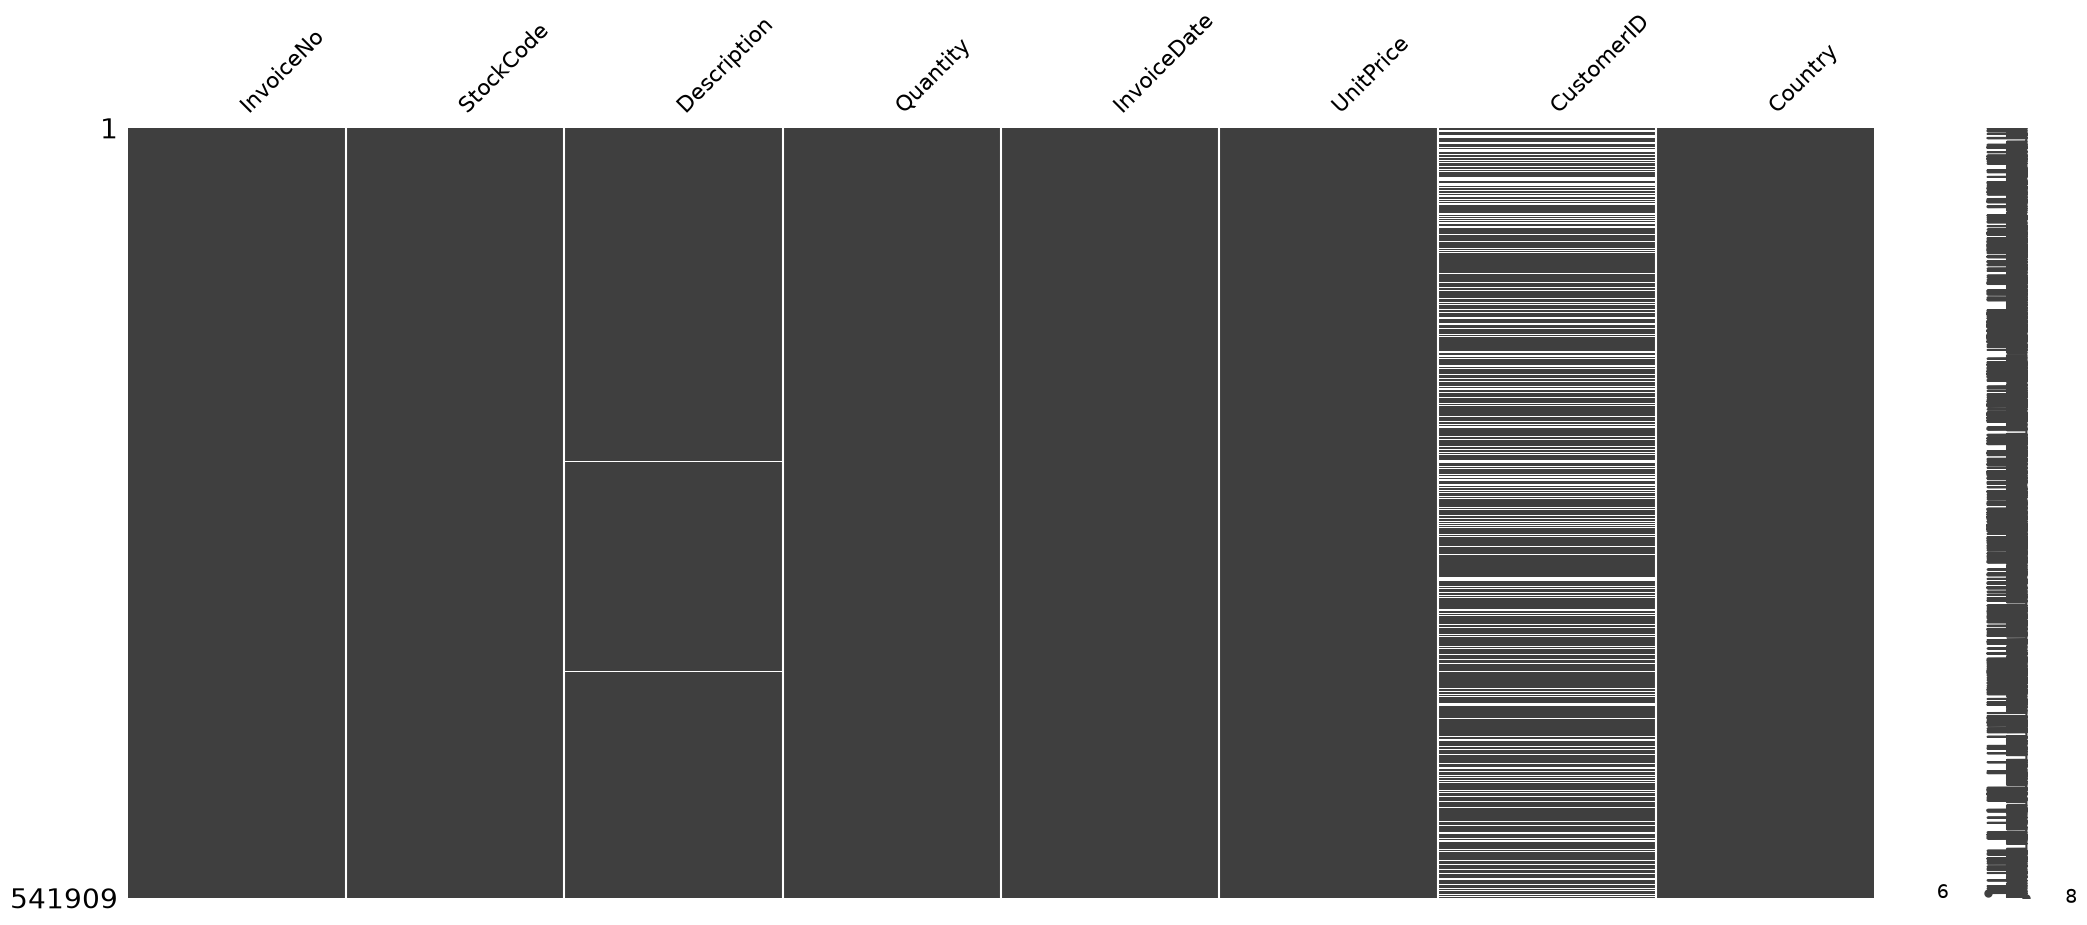

In [94]:
msno.matrix(df)

<Axes: >

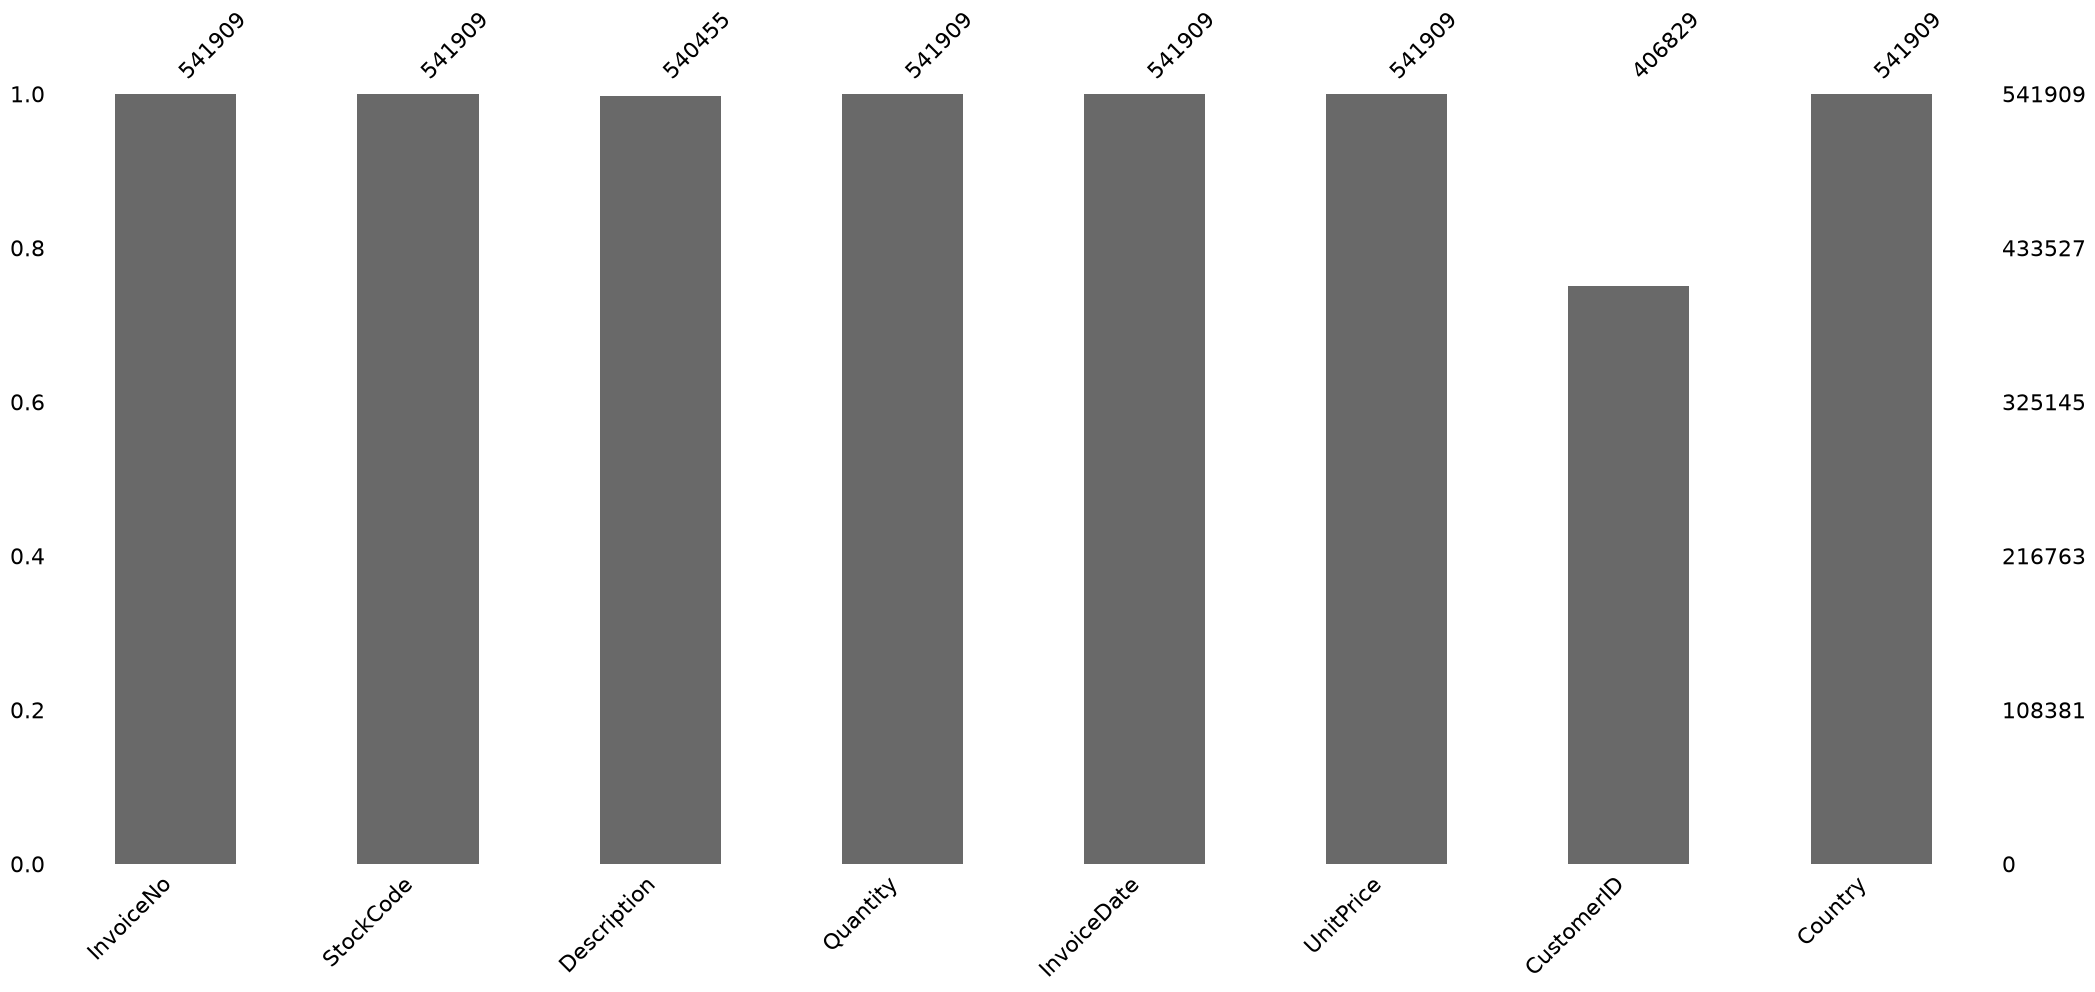

In [95]:
msno.bar(df)


### Key Findings

The dataset contains missing values in only two columns: `CustomerID` (24.93%) and `Description` (0.27%). All other columns are complete. Missing customer identifiers may limit customer-level analysis, while the small proportion of missing descriptions is less likely to affect the overall analysis significantly. No missing values have been imputed or removed at this stage.


In [96]:
duplicate_mask = df.duplicated(keep=False)
print("Total duplicate rows:", duplicate_mask.sum())

display(df[duplicate_mask])

Total duplicate rows: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
541692,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
541699,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [97]:
# Count non-positive quantities
print("Quantity <= 0:")
print((df["Quantity"] <= 0).sum())

# Count non-positive unit prices
print("\nUnitPrice <= 0:")
print((df["UnitPrice"] <= 0).sum())

# Count negative quantities
print("\nNegative Quantity:")
print((df["Quantity"] < 0).sum())

# Count zero unit prices
print("\nZero UnitPrice:")
print((df["UnitPrice"] == 0).sum())

# Count potentially cancelled invoices
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
print("\nInvoices with InvoiceNo starting with 'C':")
print(cancelled.sum())

Quantity <= 0:
10624

UnitPrice <= 0:
2517

Negative Quantity:
10624

Zero UnitPrice:
2515

Invoices with InvoiceNo starting with 'C':
9288


In [98]:
print("Cancelled invoice rows:", cancelled.sum())
print("Total rows:", len(df))
print("Percentage:", round(cancelled.mean() * 100, 2), "%")

Cancelled invoice rows: 9288
Total rows: 541909
Percentage: 1.71 %


In [99]:
negative_quantity_mask = df["Quantity"] < 0

print("Cancelled rows with negative Quantity:",
      (cancelled & negative_quantity_mask).sum())

print("Negative Quantity rows without C prefix:",
      (~cancelled & negative_quantity_mask).sum())

Cancelled rows with negative Quantity: 9288
Negative Quantity rows without C prefix: 1336


### Initial Findings: Cancelled Invoices

A total of 9,288 rows (1.71% of the dataset) have invoice numbers beginning with the prefix `C`.

All 9,288 rows also contain negative `Quantity` values. Additionally, 1,336 rows have negative `Quantity` values without the `C` prefix.

These findings show that negative quantities are associated with cancelled invoices but are not exclusive to them. Therefore, negative quantities should not automatically be classified as anomalies or removed without further investigation.

The analysis identifies potentially meaningful transaction patterns that require additional examination before selecting anomaly detection methods.

In [100]:
print("Zero UnitPrice:", (df["UnitPrice"] == 0).sum())
print("Negative UnitPrice:", (df["UnitPrice"] < 0).sum())

Zero UnitPrice: 2515
Negative UnitPrice: 2


In [101]:
non_positive_price_mask = df["UnitPrice"] <= 0

display(
    df.loc[
        non_positive_price_mask,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]
    ].sort_values("UnitPrice")
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN
536908,581226,23090,missing,-338,2011-12-08 09:56:00,0.00,NaN
535336,581213,22576,check,-30,2011-12-07 18:38:00,0.00,NaN
535335,581212,22578,lost,-1050,2011-12-07 18:38:00,0.00,NaN
...,...,...,...,...,...,...,...
538504,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.00,NaN
538505,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.00,NaN
538554,581408,85175,NaN,20,2011-12-08 14:06:00,0.00,NaN
538919,581422,23169,smashed,-235,2011-12-08 15:24:00,0.00,NaN


In [102]:
duplicate_mask = df.duplicated(keep=False)

print("Rows involved in duplicates:", duplicate_mask.sum())

display(
    df.loc[duplicate_mask]
      .sort_values(by=df.columns.tolist())
      .head(10)
)

Rows involved in duplicates: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


### Duplicate Records

The initial duplicate check identified 5,268 duplicate rows when keeping the first occurrence of each record.

When all occurrences of duplicated records were included, 10,147 rows were identified as belonging to duplicate groups.

The inspected examples contain identical values across transaction identifiers, product details, quantities, timestamps, prices, customer identifiers, and countries.

However, identical rows should not automatically be removed. Further investigation is needed to determine whether they represent redundant records or legitimate repeated entries within the same invoice.

No duplicate records have been removed at this stage.

In [103]:
invoice_id = "536409"

display(
    df[df["InvoiceNo"].astype(str) == invoice_id]
    .sort_values(["StockCode", "Quantity"])
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
512,536409,16238,PARTY TIME PENCIL ERASERS,28,2010-12-01 11:45:00,0.21,17908.0,United Kingdom
513,536409,20668,DISCO BALL CHRISTMAS DECORATION,24,2010-12-01 11:45:00,0.12,17908.0,United Kingdom
495,536409,20669,RED HEART LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
522,536409,20713,JUMBO BAG OWLS,1,2010-12-01 11:45:00,1.95,17908.0,United Kingdom
535,536409,20717,STRAWBERRY SHOPPER BAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
536,536409,20723,STRAWBERRY CHARLOTTE BAG,1,2010-12-01 11:45:00,0.85,17908.0,United Kingdom
523,536409,20966,SANDWICH BATH SPONGE,2,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
519,536409,21065,BOOM BOX SPEAKER GIRLS,1,2010-12-01 11:45:00,5.95,17908.0,United Kingdom
524,536409,21116,OWL DOORSTOP,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
518,536409,21326,AGED GLASS SILVER T-LIGHT HOLDER,12,2010-12-01 11:45:00,0.65,17908.0,United Kingdom


In [ ]:
from thefuzz import process, fuzz

descriptions = (
    df["Description"]
    .dropna()
    .astype(str)
    .str.strip()
)

unique_descriptions = descriptions.unique().tolist()

query = unique_descriptions[0]

matches = process.extract(
    query,
    unique_descriptions,
    scorer=fuzz.ratio,
    limit=10
)

print("Query:", query)

display(pd.DataFrame(
    matches,
    columns=["Description", "Similarity Score"]
))

Query: WHITE HANGING HEART T-LIGHT HOLDER


,Description,Similarity Score
0,WHITE HANGING HEART T-LIGHT HOLDER,100
1,RED HANGING HEART T-LIGHT HOLDER,91
2,PINK HANGING HEART T-LIGHT HOLDER,90
3,CREAM HANGING HEART T-LIGHT HOLDER,88
4,HANGING HEART JAR T-LIGHT HOLDER,85
5,HANGING HEART ZINC T-LIGHT HOLDER,84
6,SILVER HANGING T-LIGHT HOLDER,79
7,HANGING JAM JAR T-LIGHT HOLDER,78
8,HANGING JAM JAR T-LIGHT HOLDERS,77
9,ZINC HEART T-LIGHT HOLDER,77



### Preliminary Fuzzy Matching of Product Descriptions

The `thefuzz` library was used to explore textual similarities among unique product descriptions.

The initial example showed high similarity scores between descriptions of hanging heart tea-light holders in different colors and variations.

These results demonstrate that fuzzy matching can identify related product descriptions. However, high textual similarity does not necessarily indicate duplicate records or anomalous transactions.

This check is exploratory only. No descriptions or records have been modified or removed based on similarity scores.


---------


## 10. Numeric Distributions and Skewness

### Objectives

This section examines the distributions of numerical features to understand their central tendencies, variability, and skewness.

The analysis focuses on `Quantity` and `UnitPrice`, which describe transaction quantities and product prices.

The following statistics will be examined:

- Mean and median
- Minimum and maximum values
- Standard deviation
- Skewness

These statistics help identify highly skewed distributions and extreme values that may be relevant to anomaly detection. No records will be removed or transformed during this stage.


In [107]:
numeric_features = ["Quantity", "UnitPrice"]

distribution_summary = df[numeric_features].describe().T

distribution_summary["skewness"] = (
    df[numeric_features].skew()
)

display(distribution_summary.round(3))


,count,mean,std,min,25%,50%,75%,max,skewness
Quantity,541909.0,9.552,218.081,-80995.00,1.00,3.00,10.00,80995.0,-0.264
UnitPrice,541909.0,4.611,96.760,-11062.06,1.25,2.08,4.13,38970.0,186.507


In [108]:
negative_summary = pd.DataFrame({
    "Negative Count": (df[["Quantity", "UnitPrice"]] < 0).sum(),
    "Negative Percentage": (
        (df[["Quantity", "UnitPrice"]] < 0).mean() * 100
    ).round(2)
})

display(negative_summary)

,Negative Count,Negative Percentage
Quantity,10624,1.96
UnitPrice,2,0.00


In [109]:
df_analysis = df[
    (df["Quantity"] >= 0) &
    (df["UnitPrice"] >= 0)
].copy()

print("Original dataset shape:", df.shape)
print("Filtered dataset shape:", df_analysis.shape)
print("Rows removed:", len(df) - len(df_analysis))

Original dataset shape: (541909, 8)
Filtered dataset shape: (531283, 8)
Rows removed: 10626



### Handling Negative Values

Negative values were identified in `Quantity` and `UnitPrice`. Specifically, 10,624 rows contained negative quantities, while 2 rows contained negative unit prices.

For the subsequent analysis, a separate dataset (`df_analysis`) was created by excluding rows where either `Quantity` or `UnitPrice` was negative.

This filtering removed 10,626 rows (approximately 1.96% of the original dataset), leaving 531,283 rows for further analysis. The original dataset (`df`) remains unchanged.

This decision is a preprocessing choice rather than proof that the removed records are anomalies. Negative quantities may represent product returns, and negative prices may represent accounting adjustments. The potential effect of excluding these records should be considered when interpreting the results.


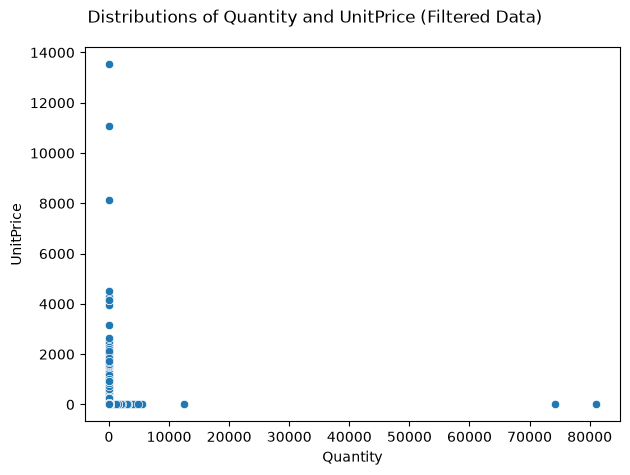

In [ ]:
fig, ax = plt.subplots()
sns.scatterplot(df_analysis, x='Quantity', y='UnitPrice')


plt.suptitle("Distributions of Quantity and UnitPrice (Filtered Data)")

plt.tight_layout()
plt.show()

In [132]:
print("Quantity quantiles:")
display(df_analysis["Quantity"].quantile(
    [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
))

print("UnitPrice quantiles:")
display(df_analysis["UnitPrice"].quantile(
    [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
))

Quantity quantiles:


0.00        1.0
0.25        1.0
0.50        3.0
0.75       10.0
0.90       24.0
0.95       30.0
0.99      100.0
1.00    80995.0
Name: Quantity, dtype: float64

UnitPrice quantiles:


0.00        0.00
0.25        1.25
0.50        2.08
0.75        4.13
0.90        7.95
0.95        9.95
0.99       16.98
1.00    13541.33
Name: UnitPrice, dtype: float64

In [137]:
df_plot = df_analysis.copy()

df_plot["Quantity_Category"] = pd.cut(
    df_plot["Quantity"],
    bins=[-np.inf, 1, 3, 10, 100, np.inf],
    labels=["Very Low", "Low", "Medium", "High", "Extreme"],
    include_lowest=True
)
df_plot

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Quantity_Category
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Medium
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Medium
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Medium
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Medium
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Medium
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,High
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,Medium
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,Medium
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,Medium


<Axes: xlabel='Quantity_Category', ylabel='UnitPrice'>

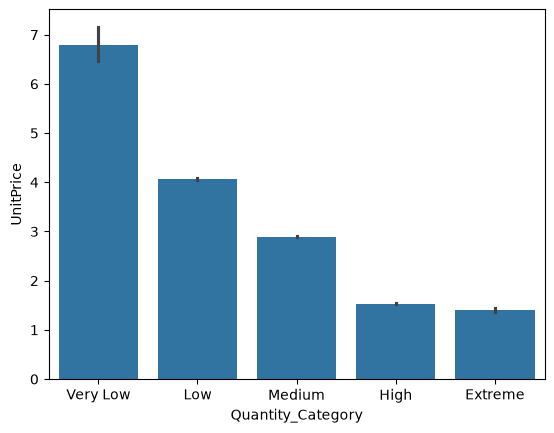

In [145]:
sns.barplot(df_plot, x='Quantity_Category', y='UnitPrice')

### Analysis 1: Mean Unit Price by Quantity Category

* **Inverse Price-Quantity Relationship:** A clear inverse trend is visible; the average `UnitPrice` drops sharply as the purchase volume category scales from `Very Low` to `Extreme`.
* **Niche & Luxury Items (`Very Low`):** The `Very Low` category exhibits the highest mean unit price (~6.8), indicating premium, luxury, or specialized items purchased in minimal quantities.
* **Bulk & Low-Cost Goods (`High` / `Extreme`):** Conversely, `High` and `Extreme` categories record the lowest mean unit prices (~1.4), reflecting high-volume purchases of low-cost, fast-moving items.


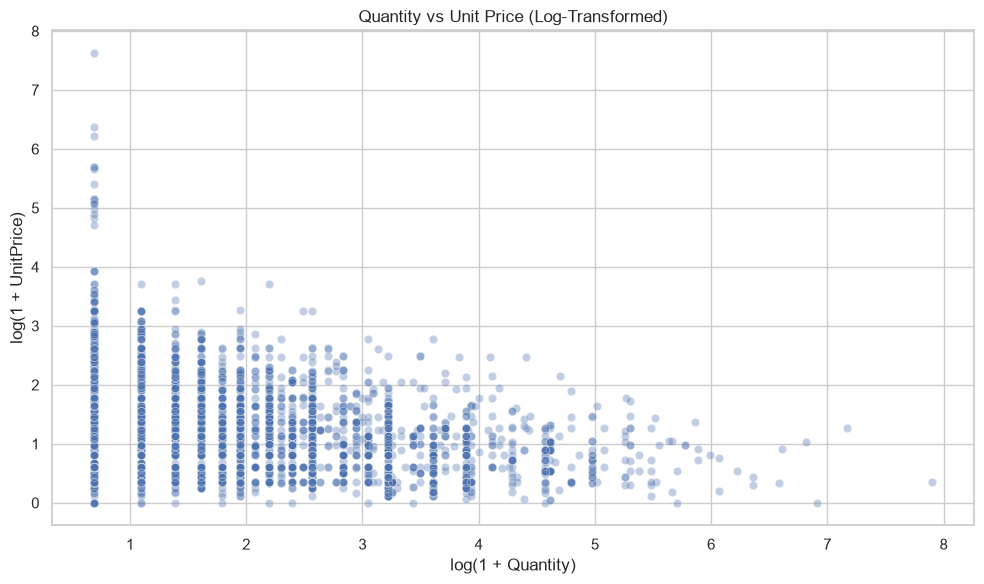

In [188]:
plot_data = df_analysis.sample(10000, random_state=42).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_data,
    x=np.log1p(plot_data["Quantity"]),
    y=np.log1p(plot_data["UnitPrice"]),
    alpha=0.35
)

plt.xlabel("log(1 + Quantity)")
plt.ylabel("log(1 + UnitPrice)")
plt.title("Quantity vs Unit Price (Log-Transformed)")
plt.tight_layout()
plt.show()

### Analysis: `Quantity vs UnitPrice` Scatter Plot — Numeric Distributions and Skewness

* **Severe Right-Skewness Evidence:** The raw distributions of both `Quantity` and `UnitPrice` are heavily right-skewed; the raw data spans several orders of magnitude, which is why the `log(1 + x)` transformation was applied purely for visualization purposes.
* **Central Tendency vs. Variability:** The dense vertical bands at low quantities (log scale 0–2) reveal that the bulk of transactions cluster around small quantities and low-to-moderate prices — indicating that the **mean** is pulled upward by extreme values, while the **median** better represents the typical transaction.
* **Extreme Values (Not Outliers Removed):** Points scattered along the far right (log Quantity up to ~8, i.e., quantities in the tens of thousands) and the isolated high-price points (~7 on the log price axis) confirm the presence of extreme values. In line with the section's objective, **no records are removed or transformed** — these extremes are flagged for downstream anomaly detection instead.
* **Structural Pattern:** The visible downward-sloping upper envelope (as quantity increases, the price ceiling drops) suggests a systematic, non-random relationship — a valuable prior for distinguishing genuine anomalies from structured bulk transactions.


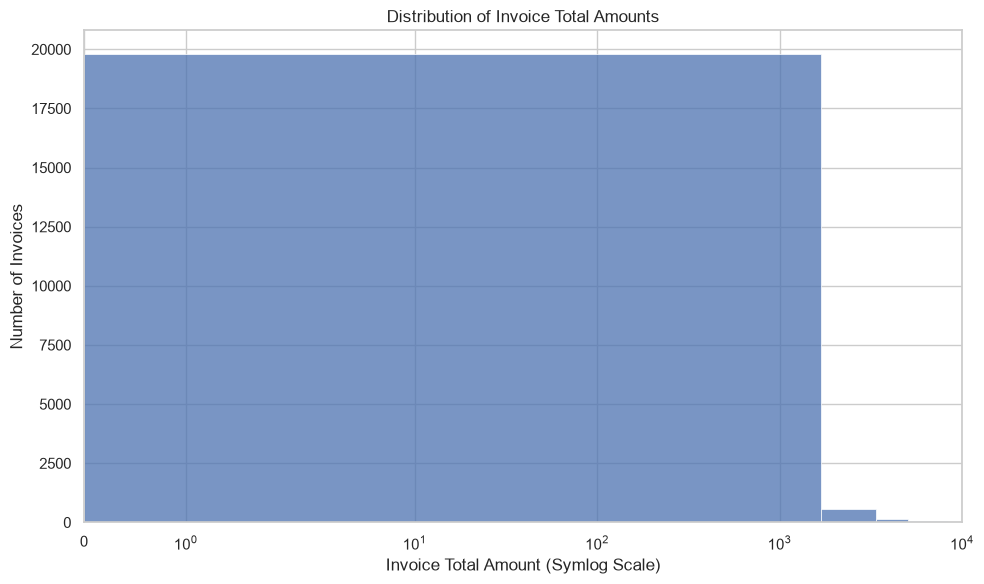

In [190]:
invoice_data = df_analysis.copy()

invoice_data["LineTotal"] = (
    invoice_data["Quantity"] * invoice_data["UnitPrice"]
)

invoice_totals = (
    invoice_data.groupby("InvoiceNo")
    .agg(
        TotalAmount=("LineTotal", "sum"),
        TotalItems=("Quantity", "sum"),
        NumberOfProducts=("StockCode", "count")
    )
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=invoice_totals,
    x="TotalAmount",
    bins=100
)

plt.xlim(0, 10000)
plt.xscale("symlog")
plt.xlabel("Invoice Total Amount (Symlog Scale)")
plt.ylabel("Number of Invoices")
plt.title("Distribution of Invoice Total Amounts")
plt.tight_layout()
plt.show()

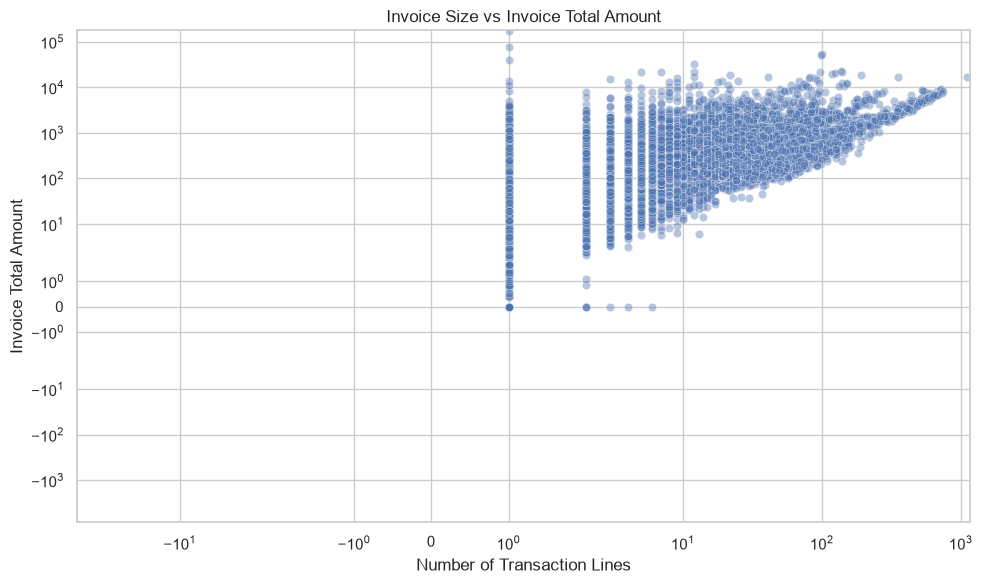

In [191]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=invoice_totals,
    x="NumberOfProducts",
    y="TotalAmount",
    alpha=0.4
)

plt.xscale("symlog")
plt.yscale("symlog")
plt.xlabel("Number of Transaction Lines")
plt.ylabel("Invoice Total Amount")
plt.title("Invoice Size vs Invoice Total Amount")
plt.tight_layout()
plt.show()

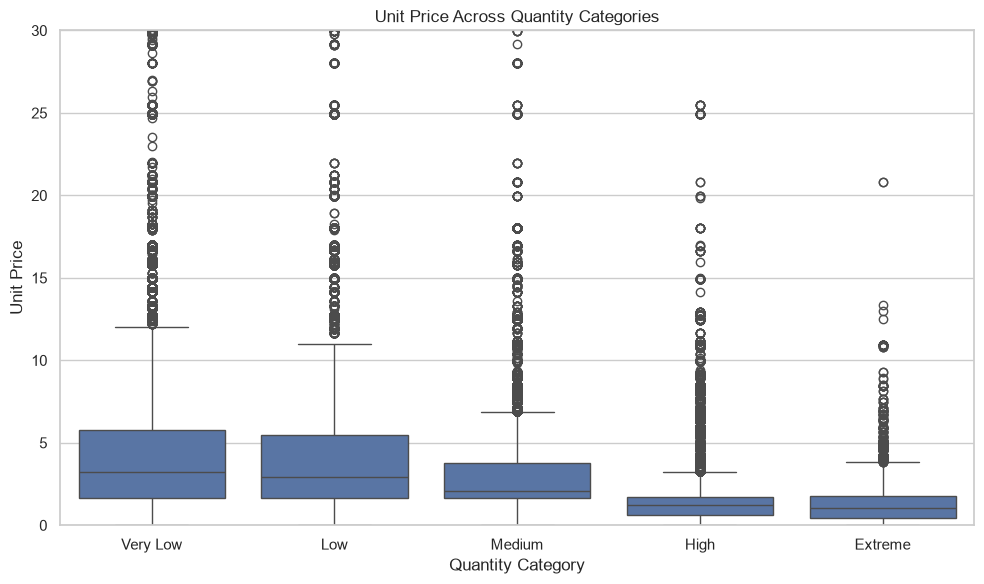

In [192]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_plot,
    x="Quantity_Category",
    y="UnitPrice"
)

plt.ylim(0, 30)
plt.xlabel("Quantity Category")
plt.ylabel("Unit Price")
plt.title("Unit Price Across Quantity Categories")
plt.tight_layout()
plt.show()

### Key Findings

The median unit price decreases as the quantity category increases. Transactions in the `High` and `Extreme` categories generally have lower unit prices than those in the `Very Low` and `Low` categories. However, high-price observations are present across all quantity categories.

### Conclusion

The results suggest an inverse relationship between purchase quantity and unit price. High unit prices within the `High` and `Extreme` categories may warrant further investigation, but they cannot be classified as anomalies based on this plot alone.

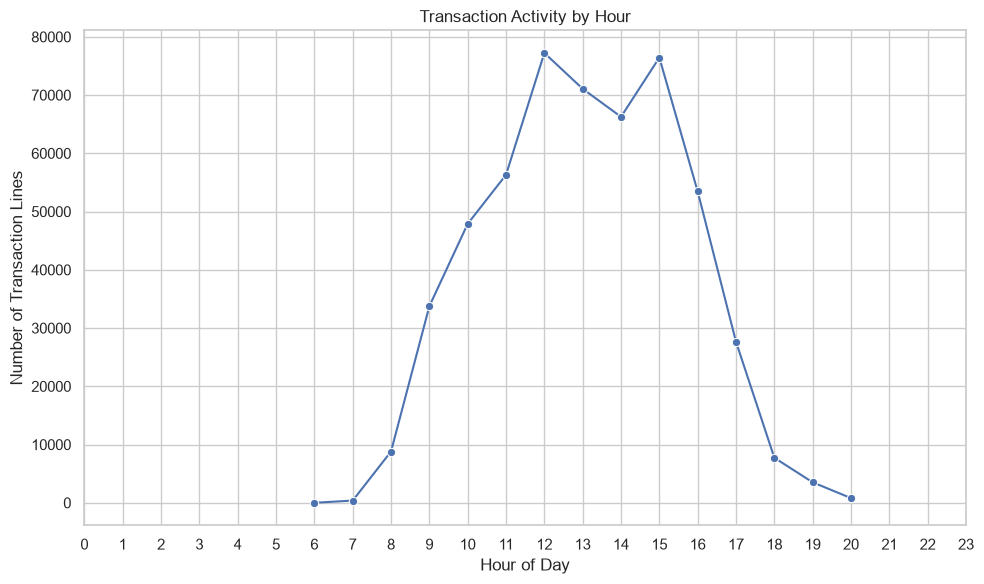

In [193]:
time_data = df_analysis.copy()

time_data["Hour"] = time_data["InvoiceDate"].dt.hour

hourly_counts = (
    time_data.groupby("Hour")
    .size()
    .reset_index(name="TransactionLines")
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=hourly_counts,
    x="Hour",
    y="TransactionLines",
    marker="o"
)

plt.xticks(range(0, 24, 1))
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transaction Lines")
plt.title("Transaction Activity by Hour")
plt.tight_layout()
plt.show()

### Key Findings

Transaction activity increases substantially during the morning, reaching its highest levels around 12:00 and 15:00. Activity decreases after 15:00 and becomes considerably lower during the evening hours.

### Conclusion

The hour of the transaction may be a useful feature for identifying unusual temporal behavior. However, transactions occurring during less active hours are not necessarily anomalous. The observed counts represent transaction lines rather than unique invoices.

In [198]:
distribution_summary

,count,mean,std,min,25%,50%,75%,max,skewness
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0,-0.264076
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0,186.506972


*****

\### Numeric Distributions and Skewness

The analysis of the numerical features revealed the following characteristics:

- \*\*Quantity distribution:\*\* The `Quantity` variable ranges from -80,995 to 80,995, with a median of 3 and a mean of approximately 9.55. Its skewness is approximately -0.264, indicating a relatively low overall skewness despite the presence of extreme values.
- \*\*Unit price distribution:\*\* The `UnitPrice` variable ranges from -11,062.06 to 38,970, with a median of 2.08 and a mean of approximately 4.61. Its skewness is approximately 186.51, indicating an extremely pronounced positive skew.
- \*\*Central tendency:\*\* The mean exceeds the median for both variables, particularly for `UnitPrice`. This difference suggests that extreme positive values influence the arithmetic mean.
- \*\*Extreme values:\*\* Both variables contain negative values and observations with large absolute magnitudes. These values require further investigation to distinguish legitimate business activity, returns, cancellations, and potential anomalies.
- \*\*Feature relationship:\*\* The previously examined scatter plot suggests a downward-sloping upper envelope between `Quantity` and `UnitPrice`. This pattern may reflect underlying commercial relationships, although the plot alone cannot establish its cause.
- \*\*Data integrity:\*\* The `log(1 + x)` transformation was used solely for visualization. The original data remain unchanged, and no records were removed or transformed during this stage.

These findings highlight the differences in the distributional characteristics of the numerical features. In particular, the extreme positive skewness of `UnitPrice` motivates further investigation of conventional Z-Score thresholds alongside robust alternatives, including the IQR rule and the Modified Z-Score based on the median absolute deviation (MAD).

The negative skewness value for `Quantity` also demonstrates that extreme values do not necessarily produce a large positive skewness coefficient. Its distribution should therefore be assessed using both numerical summaries and graphical analysis.

No data cleaning, filtering, or transformation has been performed at this stage.